In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif']=['Microsoft YaHei']
plt.rcParams['font.serif']=['Microsoft YaHei']

In [48]:
import seaborn as sns

# 准备数据

In [3]:
data=pd.read_csv('不满意率分析.csv')
data.head(2)

,序号,站点名称,骑手名称,顾客配送评分,顾客配送评价标签,顾客评价内容,订单备注,骑手接单时长,到店时长,到店等餐时长,送达时长,备注：\n1、分析差评原因，并给出改善方案；\n2、骑手姓名重复默认为同一个骑手；同一个骑手可能在不同站点出现差评\n
0,1,站点E,林*鹏,1,送达超时,NaN,NaN,2.75,19.88,0.80,68.67,NaN
1,2,站点E,张*安,1,其他,NaN,NaN,0.07,6.87,1.93,6.30,NaN


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 542 entries, 0 to 541
Data columns (total 12 columns):
 #   Column                                                    Non-Null Count  Dtype  
---  ------                                                    --------------  -----  
 0   序号                                                        542 non-null    int64  
 1   站点名称                                                      542 non-null    object 
 2   骑手名称                                                      542 non-null    object 
 3   顾客配送评分                                                    542 non-null    int64  
 4   顾客配送评价标签                                                  542 non-null    object 
 5   顾客评价内容                                                    255 non-null    object 
 6   订单备注                                                      122 non-null    object 
 7   骑手接单时长                                                    542 non-null    float64
 8   到店时长                

In [22]:
label=data['顾客配送评价标签'].str.replace('/','')
label2=label.str.split('|')

In [32]:
label2[538]

['送达超时', '态度不好', '其他']

In [13]:
total_list=[]
for i in label:
    for j in i:
        total_list.append(j)

In [17]:
bz=list(set(total_list))
bz

['少餐洒餐', '送错餐品', '仪表不整', '送达不通知', '其他', '提前点送达', '骚扰威胁', '送达超时', '态度不好']

In [34]:
d_list=[]
for i in label2:
    a=' '.join(i)
    d_list.append(a)

In [35]:
d_list

['送达超时',
 '其他',
 '送达超时 态度不好',
 '送达超时',
 '送达超时',
 '其他',
 '送达超时',
 '送达不通知',
 '送达不通知 送达超时',
 '提前点送达 态度不好 送达不通知',
 '送达不通知 提前点送达 态度不好 少餐洒餐',
 '送达超时 少餐洒餐',
 '少餐洒餐',
 '其他',
 '送达超时 态度不好 送达不通知',
 '提前点送达',
 '送错餐品',
 '送错餐品',
 '送达超时 提前点送达',
 '仪表不整',
 '送达不通知',
 '送达超时',
 '少餐洒餐',
 '送达不通知',
 '送达超时',
 '态度不好',
 '态度不好',
 '送达超时 其他',
 '少餐洒餐',
 '送达超时 少餐洒餐',
 '态度不好',
 '送达超时',
 '送达超时 其他',
 '少餐洒餐',
 '少餐洒餐',
 '送达超时',
 '送达超时',
 '态度不好',
 '送达超时',
 '送达超时',
 '其他 少餐洒餐',
 '送达超时',
 '送达超时',
 '少餐洒餐',
 '少餐洒餐',
 '送错餐品 态度不好 送达超时 其他',
 '提前点送达',
 '其他',
 '提前点送达',
 '少餐洒餐',
 '态度不好',
 '送达超时',
 '态度不好',
 '送达超时',
 '其他',
 '态度不好',
 '送达不通知',
 '送达超时',
 '送达超时',
 '送达超时',
 '态度不好 其他',
 '态度不好',
 '其他',
 '仪表不整 态度不好',
 '少餐洒餐',
 '送达超时',
 '送达超时',
 '送达超时',
 '送达超时',
 '其他',
 '送达超时',
 '送达超时',
 '送达超时 态度不好',
 '送达超时',
 '送达超时',
 '态度不好',
 '态度不好 仪表不整 少餐洒餐 提前点送达 送达超时',
 '送达超时',
 '态度不好',
 '送达超时',
 '其他 提前点送达',
 '送达超时',
 '送达超时 少餐洒餐',
 '送达超时',
 '送达超时',
 '送达超时',
 '态度不好',
 '其他 仪表不整 送达不通知 骚扰威胁 送错餐品 提前点送达 送达超时 少餐洒餐 态度不好',
 '其他',
 '仪表不整 态度不好 送达超时 提前点送达',
 '少餐洒餐',
 '

In [36]:
from sklearn.feature_extraction.text import CountVectorizer
CV=CountVectorizer()
CV.fit_transform(d_list).toarray()

array([[0, 0, 0, ..., 1, 0, 0],
       [0, 1, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 1, 0, 0],
       ...,
       [0, 0, 0, ..., 1, 0, 0],
       [0, 0, 1, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])

In [38]:
CV.get_feature_names_out()

array(['仪表不整', '其他', '少餐洒餐', '态度不好', '提前点送达', '送达不通知', '送达超时', '送错餐品',
       '骚扰威胁'], dtype=object)

In [40]:
cus_labels=pd.DataFrame(data=CV.fit_transform(d_list).toarray(),columns=CV.get_feature_names_out())

In [42]:
data=pd.concat([data,cus_labels],axis=1)

# 差评分析

## 差评原因分析

In [47]:
count1=cus_labels.sum().sort_values(ascending=False)

C:\Users\lenovo\AppData\Local\Temp\ipykernel_13088\3601354793.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(count1,palette='Set2')


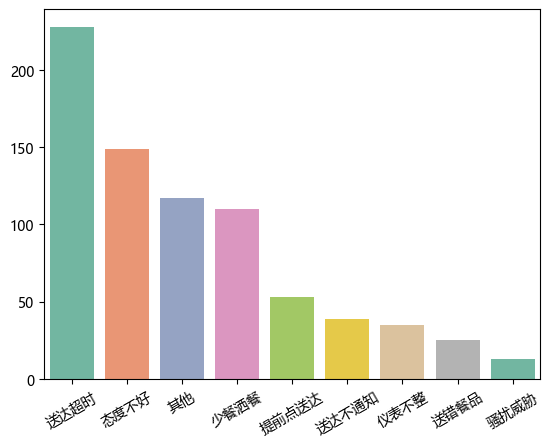

In [57]:
sns.barplot(count1,palette='Set2')
_=plt.xticks(rotation=30)

- 从四个方面入手分析
- 骑手接单时长
- 到店时长
- 到店等餐时长
- 送达时长

In [62]:
col=['骑手接单时长','到店时长','到店等餐时长','送达时长']

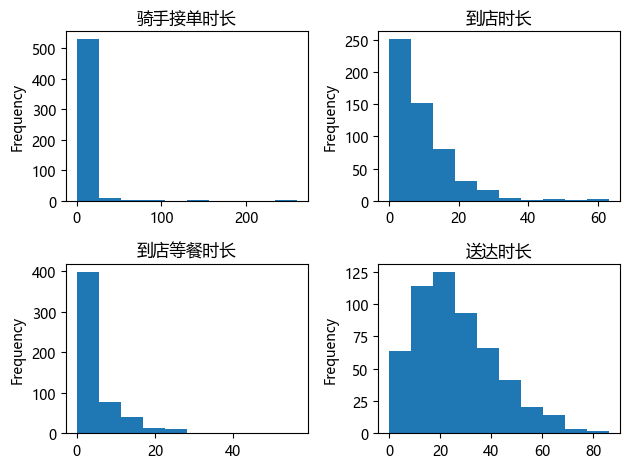

In [70]:
# 全体四维度分布
for i in range(1,5):
    plt.subplot(2,2,i)
    data[col[i-1]].plot(kind='hist',title=col[i-1])
plt.tight_layout()

{'骑手接单时长': np.float64(5.747894736842105),
 '到店时长': np.float64(11.272587719298244),
 '到店等餐时长': np.float64(3.8973245614035084),
 '送达时长': np.float64(32.217368421052626)}

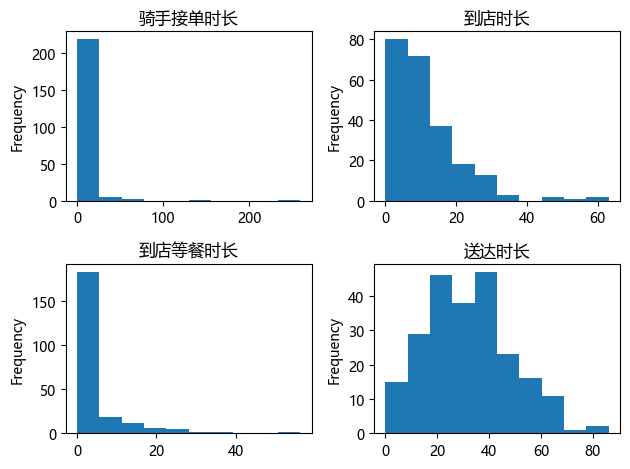

In [83]:
# 送达超时群体四维度分布
chaoshi={}
for i in range(1,5):
    plt.subplot(2,2,i)
    data.loc[data['送达超时']==1,col[i-1]].plot(kind='hist',title=col[i-1])
    chaoshi[col[i-1]]=data.loc[data['送达超时']==1,col[i-1]].mean()
plt.tight_layout()
chaoshi

{'骑手接单时长': np.float64(2.974904458598726),
 '到店时长': np.float64(7.3070382165605094),
 '到店等餐时长': np.float64(4.595445859872612),
 '送达时长': np.float64(21.617197452229302)}

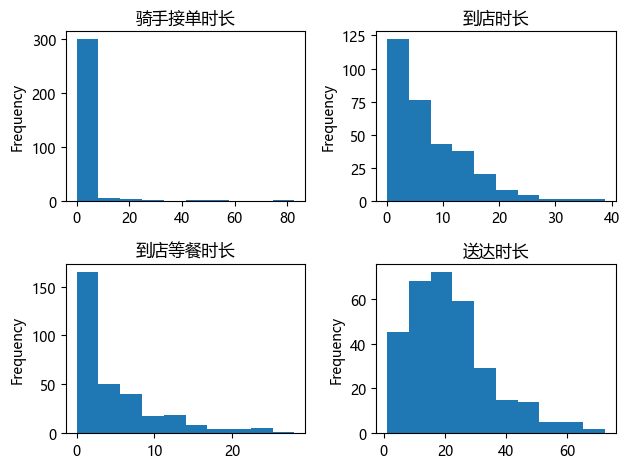

In [84]:
# 送达准时群体四维度分布
zshi={}
for i in range(1,5):
    plt.subplot(2,2,i)
    data.loc[data['送达超时']!=1,col[i-1]].plot(kind='hist',title=col[i-1])
    zshi[col[i-1]]=data.loc[data['送达超时']!=1,col[i-1]].mean()
plt.tight_layout()
zshi

In [91]:
duib=pd.DataFrame({'准时送达':zshi,'超时送达':chaoshi})
duib

,准时送达,超时送达
骑手接单时长,2.974904,5.747895
到店时长,7.307038,11.272588
到店等餐时长,4.595446,3.897325
送达时长,21.617197,32.217368


(array([0, 1, 2, 3]),
 [Text(0, 0, '骑手接单时长'),
  Text(1, 0, '到店时长'),
  Text(2, 0, '到店等餐时长'),
  Text(3, 0, '送达时长')])

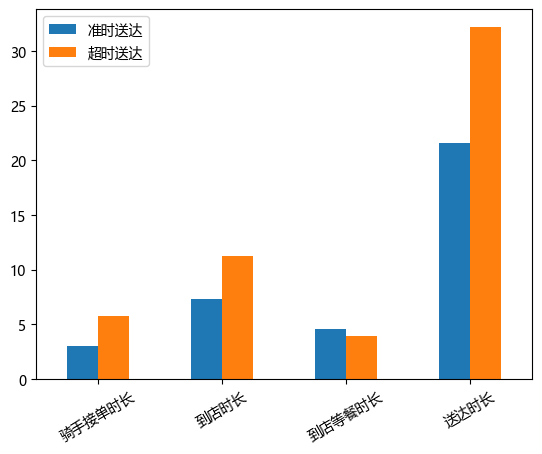

In [96]:
duib.plot(kind='bar')
plt.xticks(rotation=30)

1. 对比图可看出，可以着重优化到店的时长和送达时长，使其减少所花时间，以便能按时送达
2. 可以从派单距离入手，适当降低

## 站点维度

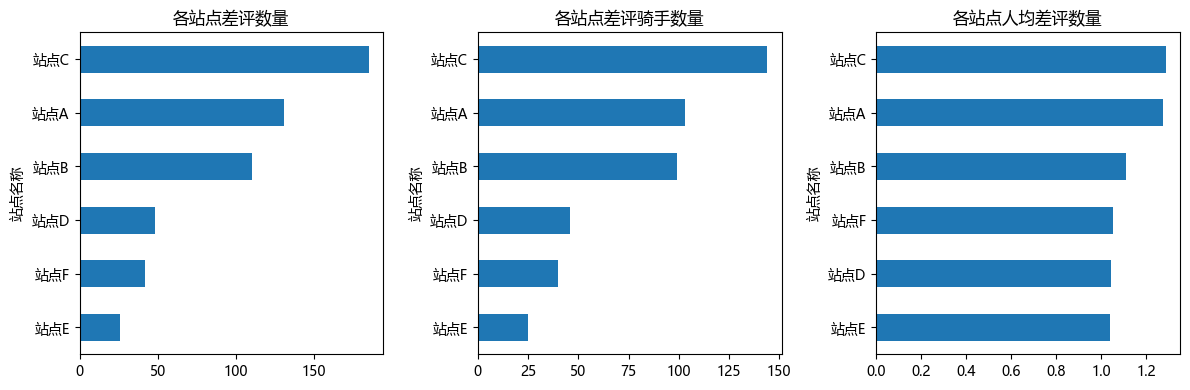

In [137]:
plt.figure(figsize=(12,4))

plt.subplot(131)
a=data.groupby('站点名称')['站点名称'].count()
a.sort_values(ascending=True).plot(kind='barh')
plt.title('各站点差评数量')

plt.subplot(132)
# data中全是差评，所以直接用data整体
b=data.groupby('站点名称')['骑手名称'].nunique()
b.sort_values(ascending=True).plot(kind='barh')
plt.title('各站点差评骑手数量')

plt.subplot(133)
c=a/b
c.sort_values(ascending=True).plot(kind='barh')
plt.title('各站点人均差评数量')

plt.tight_layout()

C:\Users\lenovo\AppData\Local\Temp\ipykernel_13088\1937907528.py:1: FutureWarning: The provided callable <built-in function sum> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  data.groupby('站点名称').agg({'仪表不整': sum,
C:\Users\lenovo\AppData\Local\Temp\ipykernel_13088\1937907528.py:1: FutureWarning: The provided callable <built-in function sum> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  data.groupby('站点名称').agg({'仪表不整': sum,


<Axes: title={'center': '各站点与差评类型数量，交叉对比'}, xlabel='站点名称'>

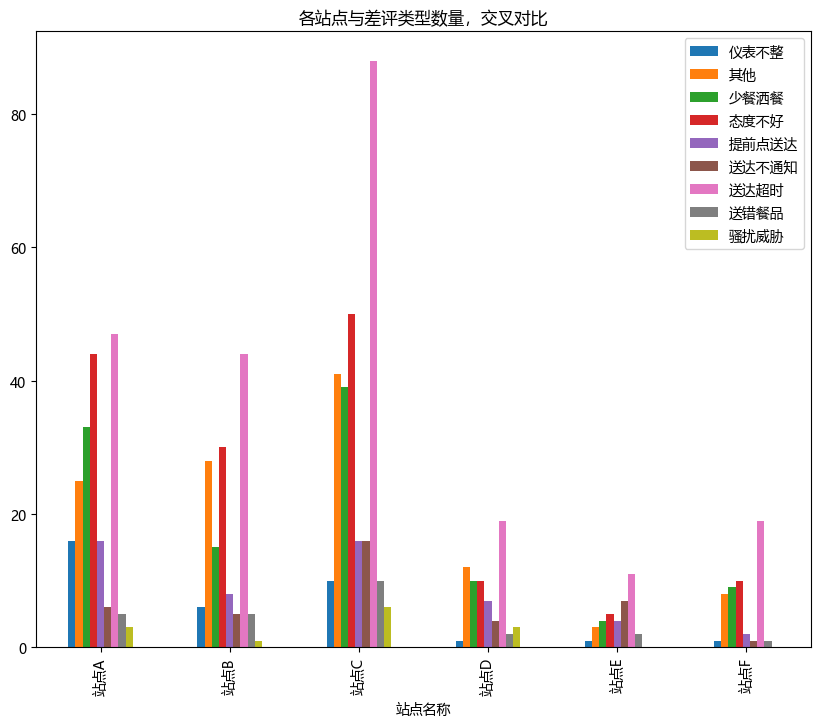

In [138]:
data.groupby('站点名称').agg({'仪表不整': sum,
                         '其他': sum,
                         '少餐洒餐': sum,
                         '态度不好': sum,
                         '提前点送达': sum,
                         '送达不通知': sum,
                         '送达超时': sum,
                         '送错餐品': sum,
                         '骚扰威胁': sum,}).plot(kind='bar',
                                             figsize=(10, 8),
                          title='各站点与差评类型数量，交叉对比')

## 员工角度

In [143]:
man_top=data.groupby('骑手名称')['序号'].count().sort_values(ascending=False)[:10]

In [144]:
man_top.index

Index(['李*', '陈*', '刘*', '王*', '黄*', '张*', '杨*', '吴*霖', '李*勇', '伍*燕'], dtype='object', name='骑手名称')

In [147]:
data_top10=data.loc[data['骑手名称'].isin(man_top.index),:]

In [148]:
top10_reason_count = data_top10.groupby('骑手名称').agg({'仪表不整': sum,
                         '其他': sum,
                         '少餐洒餐': sum,
                         '态度不好': sum,
                         '提前点送达': sum,
                         '送达不通知': sum,
                         '送达超时': sum,
                         '送错餐品': sum,
                         '骚扰威胁': sum,})

C:\Users\lenovo\AppData\Local\Temp\ipykernel_13088\716109134.py:1: FutureWarning: The provided callable <built-in function sum> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  top10_reason_count = data_top10.groupby('骑手名称').agg({'仪表不整': sum,
C:\Users\lenovo\AppData\Local\Temp\ipykernel_13088\716109134.py:1: FutureWarning: The provided callable <built-in function sum> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  top10_reason_count = data_top10.groupby('骑手名称').agg({'仪表不整': sum,


In [149]:
top10_reason_count

,仪表不整,其他,少餐洒餐,态度不好,提前点送达,送达不通知,送达超时,送错餐品,骚扰威胁
骑手名称,,,,,,,,,
伍*燕,0,0,0,3,0,1,1,0,0
刘*,1,2,0,1,1,0,5,0,0
吴*霖,0,0,0,0,0,0,4,0,0
张*,0,2,1,1,0,0,1,0,0
李*,0,3,1,2,2,1,4,1,0
李*勇,0,1,0,1,0,0,2,0,0
杨*,0,1,1,0,0,0,3,0,0
王*,1,1,0,2,3,1,2,0,0
陈*,1,2,0,3,0,0,2,0,0


(array([0.5, 1.5, 2.5, 3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5]),
 [Text(0, 0.5, '伍*燕'),
  Text(0, 1.5, '刘*'),
  Text(0, 2.5, '吴*霖'),
  Text(0, 3.5, '张*'),
  Text(0, 4.5, '李*'),
  Text(0, 5.5, '李*勇'),
  Text(0, 6.5, '杨*'),
  Text(0, 7.5, '王*'),
  Text(0, 8.5, '陈*'),
  Text(0, 9.5, '黄*')])

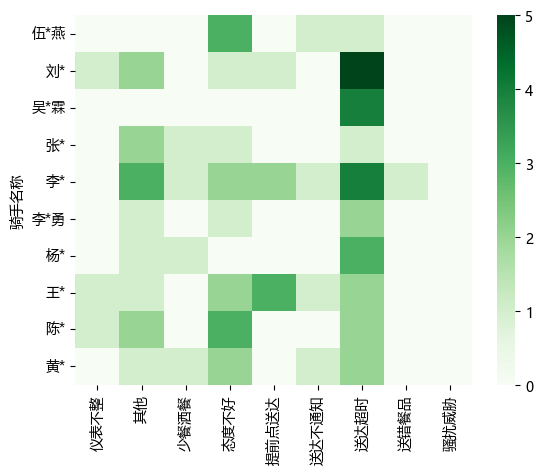

In [155]:
sns.heatmap(top10_reason_count,cmap='Greens')
plt.yticks(rotation=0)

1. 可以从热力图中看出各top10的相应维度分析

In [156]:
data[data['骚扰威胁']==1].groupby('骑手名称')['骚扰威胁'].sum()

骑手名称
伍*进    1
何*     1
农*群    1
刘*洋    1
刘*辉    1
唐*彪    1
张*希    1
梁*财    1
潘*霖    1
蒙*昌    1
陆*龙    1
陈*全    1
陈*基    1
Name: 骚扰威胁, dtype: int64

In [157]:
data[data['骚扰威胁']==1]

,序号,站点名称,骑手名称,顾客配送评分,顾客配送评价标签,顾客评价内容,订单备注,骑手接单时长,到店时长,到店等餐时长,...,备注：\n1、分析差评原因，并给出改善方案；\n2、骑手姓名重复默认为同一个骑手；同一个骑手可能在不同站点出现差评\n,仪表不整,其他,少餐洒餐,态度不好,提前点送达,送达不通知,送达超时,送错餐品,骚扰威胁
87,88,站点C,蒙*昌,1,其他|仪表不整|送达不通知|骚扰威胁|送错餐品|提前点送达|送达超时|少餐/洒餐|态度不好,NaN,有路障，送到路口路障打电话叫我即可。,1.62,0.30,12.12,...,NaN,1,1,1,1,1,1,1,1,1
134,135,站点C,伍*进,1,少餐/洒餐|骚扰威胁|送达超时|态度不好|其他|提前点送达,NaN,少冰，，珍珠多一点，珍珠多一点，珍珠多一点，珍珠多一点，谢谢你,1.23,11.70,0.15,...,NaN,0,1,1,1,1,0,1,0,1
190,191,站点C,刘*辉,1,骚扰威胁|态度不好|少餐/洒餐|其他,NaN,NaN,12.55,6.58,10.33,...,NaN,0,1,1,1,0,0,0,0,1
201,202,站点C,梁*财,1,送达超时|送错餐品|骚扰威胁|少餐/洒餐|仪表不整|送达不通知|态度不好|提前点送达,NaN,NaN,2.17,20.18,0.05,...,NaN,1,0,1,1,1,1,1,1,1
236,237,站点C,唐*彪,1,态度不好|仪表不整|少餐/洒餐|骚扰威胁|送达超时|其他,差我一瓶酒没给我,NaN,0.00,8.05,2.23,...,NaN,1,1,1,1,0,0,1,0,1
243,244,站点C,潘*霖,1,少餐/洒餐|仪表不整|骚扰威胁|态度不好|其他|送达超时,食物直接放在地上，态度极其恶劣，说脏话，超级不满意，心情不好，送餐迟到,NaN,0.77,30.90,0.02,...,NaN,1,1,1,1,0,0,1,0,1
296,297,站点A,何*,1,态度不好|仪表不整|提前点送达|骚扰威胁,NaN,多点饭老板 多打点饭,0.37,22.70,0.97,...,NaN,1,0,0,1,1,0,0,0,1
301,302,站点A,陈*基,1,送达不通知|送达超时|送错餐品|态度不好|仪表不整|提前点送达|骚扰威胁|其他|少餐/洒餐,怎么可能有人知道我的电话号码,NaN,1.63,9.95,0.07,...,NaN,1,1,1,1,1,1,1,1,1
302,303,站点A,刘*洋,1,少餐/洒餐|骚扰威胁|送达不通知,NaN,多点饭老板 多打点饭,0.68,2.07,2.38,...,NaN,0,0,1,0,0,1,0,0,1
401,402,站点D,陈*全,1,态度不好|送达超时|骚扰威胁|少餐/洒餐,送错地址还骂人，餐都洒了。而且还说我定位是错的！！还说这个定位他要是点确认收货会被扣钱要我给...,多给几包孜然粉和番茄酱谢谢,1.05,7.22,5.63,...,NaN,0,0,1,1,0,0,1,0,1
